### Executive Recommendation

**Recommendation: Hold the full rollout of the free-trial screening question.**

The experiment found that the screening question reduced free-trial enrollment conversion by approximately **2.06 percentage points**, a statistically significant result (p < 0.001).

Paid conversion declined by approximately **0.49 percentage points**, but this difference was not statistically significant (p = 0.156). Its 95% confidence interval of **−1.16 to +0.19 percentage points** does not rule out a commercially meaningful decrease.

Although fewer free-trial enrollments could reduce operational expenses, the dataset does not provide actual customer profitability or support costs. A preliminary sensitivity analysis using hypothetical financial assumptions does not establish a reliable economic benefit.

**Next decision:** Validate the actual costs and customer economics, determine an acceptable maximum reduction in paid conversion, and collect further experimental evidence if necessary before considering rollout.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/.gitignore
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/Gross conversion.svg
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/LICENSE
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/Net conversion.svg
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/README.md
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/Udacity AB Testing by Google.ipynb
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/Udacity.key
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/data/Final Project Baseline Values - Sheet1.csv
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/data/Final Project Results - Control.csv
/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/data/Final Project Results - Experiment.csv


In [2]:

import pandas as pd

path = "/kaggle/input/datasets/zacksshen/udacity-ab-testing-by-google-datasets/data/"

control = pd.read_csv(path + "Final Project Results - Control.csv")
experiment = pd.read_csv(path + "Final Project Results - Experiment.csv")
baseline = pd.read_csv(path + "Final Project Baseline Values - Sheet1.csv")

print("Control:", control.shape)
print("Experiment:", experiment.shape)

print("\nCONTROL")
display(control.head())

print("\nEXPERIMENT")
display(experiment.head())

print("\nBASELINE")
display(baseline.head())


Control: (37, 5)
Experiment: (37, 5)

CONTROL


,Date,Pageviews,Clicks,Enrollments,Payments
0,"Sat, Oct 11",7723,687,134.0,70.0
1,"Sun, Oct 12",9102,779,147.0,70.0
2,"Mon, Oct 13",10511,909,167.0,95.0
3,"Tue, Oct 14",9871,836,156.0,105.0
4,"Wed, Oct 15",10014,837,163.0,64.0



EXPERIMENT


,Date,Pageviews,Clicks,Enrollments,Payments
0,"Sat, Oct 11",7716,686,105.0,34.0
1,"Sun, Oct 12",9288,785,116.0,91.0
2,"Mon, Oct 13",10480,884,145.0,79.0
3,"Tue, Oct 14",9867,827,138.0,92.0
4,"Wed, Oct 15",9793,832,140.0,94.0



BASELINE


,Unique cookies to view course overview page per day:,40000
0,"Unique cookies to click ""Start free trial"" per...",3200.00000
1,Enrollments per day:,660.00000
2,"Click-through-probability on ""Start free trial"":",0.08000
3,"Probability of enrolling, given click:",0.20625
4,"Probability of payment, given enroll:",0.53000


In [3]:

print("CONTROL - Missing Values")
print(control.isna().sum())

print("\nEXPERIMENT - Missing Values")
print(experiment.isna().sum())


CONTROL - Missing Values
Date            0
Pageviews       0
Clicks          0
Enrollments    14
Payments       14
dtype: int64

EXPERIMENT - Missing Values
Date            0
Pageviews       0
Clicks          0
Enrollments    14
Payments       14
dtype: int64


In [4]:

# Keep days with complete enrollment and payment data
control_mature = control.dropna(subset=["Enrollments", "Payments"])
experiment_mature = experiment.dropna(subset=["Enrollments", "Payments"])

print("Control mature days:", len(control_mature))
print("Experiment mature days:", len(experiment_mature))

# Check which dates are missing outcomes
print("\nControl missing dates:")
print(control.loc[control["Payments"].isna(), "Date"].tolist())


Control mature days: 23
Experiment mature days: 23

Control missing dates:
['Mon, Nov 3', 'Tue, Nov 4', 'Wed, Nov 5', 'Thu, Nov 6', 'Fri, Nov 7', 'Sat, Nov 8', 'Sun, Nov 9', 'Mon, Nov 10', 'Tue, Nov 11', 'Wed, Nov 12', 'Thu, Nov 13', 'Fri, Nov 14', 'Sat, Nov 15', 'Sun, Nov 16']


In [5]:

control_rate = (
    control_mature["Payments"].sum()
    / control_mature["Clicks"].sum()
)

experiment_rate = (
    experiment_mature["Payments"].sum()
    / experiment_mature["Clicks"].sum()
)

print(f"Control net conversion: {control_rate:.2%}")
print(f"Experiment net conversion: {experiment_rate:.2%}")


Control net conversion: 11.76%
Experiment net conversion: 11.27%


In [6]:

print("CONTROL")
print("Clicks:", control_mature["Clicks"].sum())
print("Payments:", control_mature["Payments"].sum())

print("\nEXPERIMENT")
print("Clicks:", experiment_mature["Clicks"].sum())
print("Payments:", experiment_mature["Payments"].sum())


CONTROL
Clicks: 17293
Payments: 2033.0

EXPERIMENT
Clicks: 17260
Payments: 1945.0


In [7]:

from statsmodels.stats.proportion import proportions_ztest

# Number of paying customers
payments = [1945, 2033]

# Number of users who clicked Start Free Trial
clicks = [17260, 17293]

# Two-sided hypothesis test
z_stat, p_value = proportions_ztest(
    count=payments,
    nobs=clicks,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")


Z-statistic: -1.4192
P-value: 0.1558


In [8]:

from statsmodels.stats.proportion import confint_proportions_2indep

lower, upper = confint_proportions_2indep(
    count1=1945,
    nobs1=17260,
    count2=2033,
    nobs2=17293,
    compare="diff",
    method="newcomb"
)

print(f"95% CI: [{lower:.2%}, {upper:.2%}]")


95% CI: [-1.16%, 0.19%]


In [9]:

control_gross = (
    control_mature["Enrollments"].sum()
    / control_mature["Clicks"].sum()
)

experiment_gross = (
    experiment_mature["Enrollments"].sum()
    / experiment_mature["Clicks"].sum()
)

print(f"Control gross conversion: {control_gross:.2%}")
print(f"Experiment gross conversion: {experiment_gross:.2%}")
print(f"Difference: {(experiment_gross - control_gross):.2%}")


Control gross conversion: 21.89%
Experiment gross conversion: 19.83%
Difference: -2.06%


In [10]:

from statsmodels.stats.proportion import proportions_ztest

enrollments = [
    experiment_mature["Enrollments"].sum(),
    control_mature["Enrollments"].sum()
]

clicks = [
    experiment_mature["Clicks"].sum(),
    control_mature["Clicks"].sum()
]

z_stat, p_value = proportions_ztest(
    count=enrollments,
    nobs=clicks,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")


Z-statistic: -4.7018
P-value: 0.0000


In [11]:

control_retention = (
    control_mature["Payments"].sum()
    / control_mature["Enrollments"].sum()
)

experiment_retention = (
    experiment_mature["Payments"].sum()
    / experiment_mature["Enrollments"].sum()
)

print(f"Control retention: {control_retention:.2%}")
print(f"Experiment retention: {experiment_retention:.2%}")

print(
    f"Difference: "
    f"{(experiment_retention - control_retention):.2%}"
)


Control retention: 53.71%
Experiment retention: 56.82%
Difference: 3.11%


In [12]:

from statsmodels.stats.proportion import confint_proportions_2indep

lower, upper = confint_proportions_2indep(
    count1=int(experiment_mature["Enrollments"].sum()),
    nobs1=int(experiment_mature["Clicks"].sum()),
    count2=int(control_mature["Enrollments"].sum()),
    nobs2=int(control_mature["Clicks"].sum()),
    compare="diff",
    method="newcomb"
)

print(f"95% CI: [{lower:.2%}, {upper:.2%}]")


95% CI: [-2.91%, -1.20%]


In [13]:

print("CONTROL")
print("Pageviews:", control["Pageviews"].sum())
print("Clicks:", control["Clicks"].sum())

print("\nEXPERIMENT")
print("Pageviews:", experiment["Pageviews"].sum())
print("Clicks:", experiment["Clicks"].sum())


CONTROL
Pageviews: 345543
Clicks: 28378

EXPERIMENT
Pageviews: 344660
Clicks: 28325


In [14]:

from scipy.stats import binomtest

control_views = int(control["Pageviews"].sum())
experiment_views = int(experiment["Pageviews"].sum())

total_views = control_views + experiment_views

result = binomtest(
    k=control_views,
    n=total_views,
    p=0.5
)

print(f"Control share: {control_views / total_views:.2%}")
print(f"Experiment share: {experiment_views / total_views:.2%}")
print(f"SRM p-value: {result.pvalue:.4f}")


Control share: 50.06%
Experiment share: 49.94%
SRM p-value: 0.2884


In [15]:

from statsmodels.stats.proportion import proportions_ztest

control_ctr = control["Clicks"].sum() / control["Pageviews"].sum()
experiment_ctr = experiment["Clicks"].sum() / experiment["Pageviews"].sum()

z_stat, p_value = proportions_ztest(
    count=[
        experiment["Clicks"].sum(),
        control["Clicks"].sum()
    ],
    nobs=[
        experiment["Pageviews"].sum(),
        control["Pageviews"].sum()
    ]
)

print(f"Control CTR: {control_ctr:.2%}")
print(f"Experiment CTR: {experiment_ctr:.2%}")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")


Control CTR: 8.21%
Experiment CTR: 8.22%
Z-statistic: 0.0857
P-value: 0.9317


In [16]:

# Actual conversion-rate differences from our experiment
trials_avoided = (
    control_gross - experiment_gross
) * 10000

paying_customers_lost = (
    control_rate - experiment_rate
) * 10000

# Hypothetical business assumptions
profit_per_customer = 150
trial_costs = [5, 10, 20, 40]

results = []

for cost in trial_costs:
    savings = trials_avoided * cost
    lost_profit = paying_customers_lost * profit_per_customer
    net_impact = savings - lost_profit

    results.append({
        "Trial Cost ($)": cost,
        "Trial Savings ($)": round(savings),
        "Lost Profit ($)": round(lost_profit),
        "Net Impact ($)": round(net_impact)
    })

sensitivity = pd.DataFrame(results)

display(sensitivity)


,Trial Cost ($),Trial Savings ($),Lost Profit ($),Net Impact ($)
0,5,1028,7311,-6283
1,10,2055,7311,-5255
2,20,4111,7311,-3200
3,40,8222,7311,911


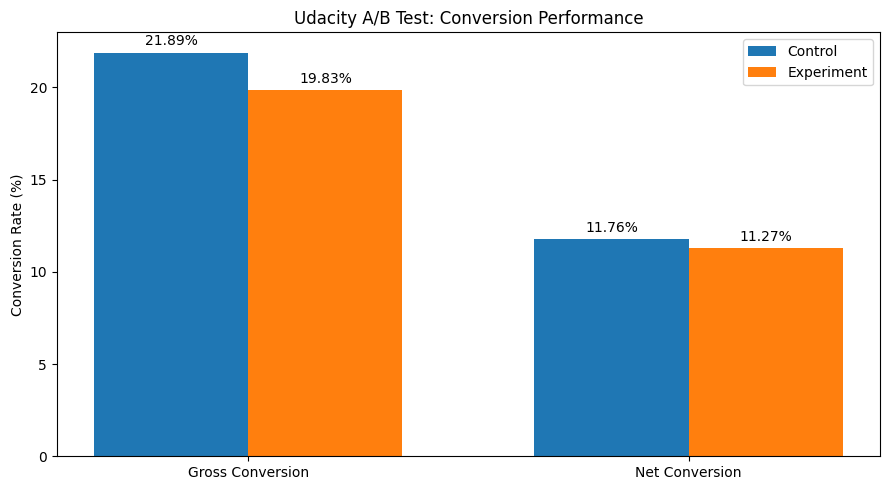

In [17]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Gross Conversion", "Net Conversion"]

control_values = [control_gross * 100, control_rate * 100]
experiment_values = [experiment_gross * 100, experiment_rate * 100]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, control_values, width, label="Control")
bars2 = ax.bar(x + width/2, experiment_values, width, label="Experiment")

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

ax.set_xticks(x, metrics)
ax.set_ylabel("Conversion Rate (%)")
ax.set_title("Udacity A/B Test: Conversion Performance")
ax.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/conversion_comparison.png", dpi=200)
plt.show()


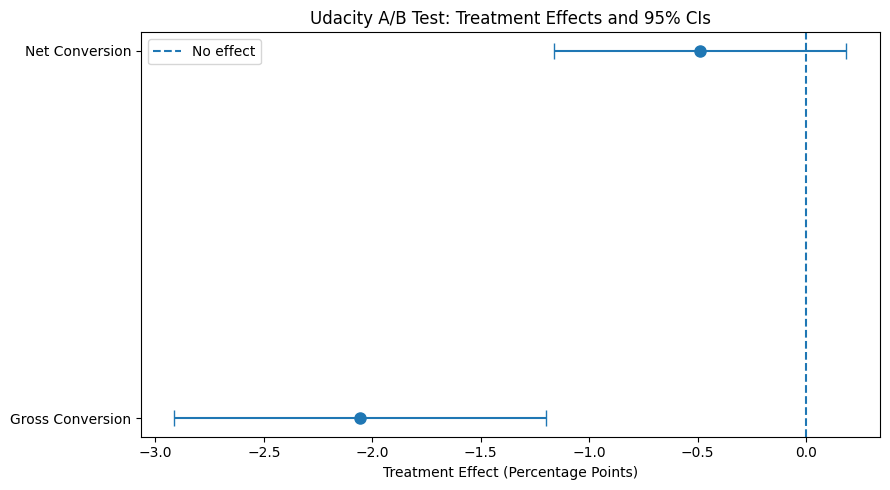

In [18]:

from statsmodels.stats.proportion import confint_proportions_2indep

outcomes = ["Enrollments", "Payments"]

effects = []
lowers = []
uppers = []

for outcome in outcomes:
    treatment_count = int(experiment_mature[outcome].sum())
    control_count = int(control_mature[outcome].sum())

    treatment_n = int(experiment_mature["Clicks"].sum())
    control_n = int(control_mature["Clicks"].sum())

    effect = treatment_count / treatment_n - control_count / control_n

    low, high = confint_proportions_2indep(
        treatment_count, treatment_n,
        control_count, control_n,
        compare="diff",
        method="newcomb"
    )

    effects.append(effect * 100)
    lowers.append(low * 100)
    uppers.append(high * 100)

errors = [
    np.array(effects) - np.array(lowers),
    np.array(uppers) - np.array(effects)
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    effects,
    ["Gross Conversion", "Net Conversion"],
    xerr=errors,
    fmt="o",
    capsize=6,
    markersize=8
)

ax.axvline(0, linestyle="--", label="No effect")
ax.set_xlabel("Treatment Effect (Percentage Points)")
ax.set_title("Udacity A/B Test: Treatment Effects and 95% CIs")
ax.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/treatment_effects.png", dpi=200)
plt.show()
